<a href="https://colab.research.google.com/github/rjngoh/credit-card-customer-segmentation/blob/main/ANL303_GBA01_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
#Suppress all warnings
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules

In [6]:
df = pd.read_csv('cardholder_campaign_data.csv')

df.head()

,Customer_ID,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
0,C0001,38,23357.0,Yes,No,No,No,No,Yes,No,No,No,No
1,C0002,32,21379.0,Yes,No,No,No,No,No,No,No,No,No
2,C0003,40,27831.0,No,Yes,No,No,No,No,No,Yes,No,No
3,C0004,48,29658.0,Yes,Yes,No,No,No,No,No,No,Yes,No
4,C0005,31,15414.0,No,Yes,Yes,No,No,Yes,No,Yes,Yes,No


In [7]:
df.set_index('Customer_ID', inplace=True)

df.head()

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0001,38,23357.0,Yes,No,No,No,No,Yes,No,No,No,No
C0002,32,21379.0,Yes,No,No,No,No,No,No,No,No,No
C0003,40,27831.0,No,Yes,No,No,No,No,No,Yes,No,No
C0004,48,29658.0,Yes,Yes,No,No,No,No,No,No,Yes,No
C0005,31,15414.0,No,Yes,Yes,No,No,Yes,No,Yes,Yes,No


In [8]:
df.describe(include='all')

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
count,777.000000,776.000000,777,777,777,777,777,777,777,777,777,777
unique,NaN,NaN,2,2,2,2,2,2,2,2,2,3
top,NaN,NaN,No,No,No,No,No,No,No,No,No,No
freq,NaN,NaN,393,465,471,712,632,444,754,700,409,399
mean,33.920206,22703.787371,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,8.738693,5952.902537,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,15.000000,4515.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,27.000000,18724.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,34.000000,22851.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,40.000000,26764.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df.sort_values('Age', ascending=True)

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0377,15,30323.0,No,No,Yes,No,No,No,No,No,No,Yes
C0482,18,15125.0,No,No,No,No,No,No,No,No,No,Yes
C0635,18,17169.0,No,No,Yes,No,No,Yes,No,No,No,Yes
C0438,18,20446.0,Yes,Yes,No,No,No,Yes,No,No,Yes,Yes
C0630,18,21609.0,Yes,Yes,No,No,No,No,No,No,Yes,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...
C0654,58,36999.0,No,Yes,Yes,No,No,Yes,No,No,No,Yes
C0755,59,35086.0,No,Yes,Yes,No,No,No,No,No,Yes,No
C0180,59,35551.0,No,Yes,Yes,No,Yes,Yes,No,No,Yes,Yes


In [10]:
df = df[df['Age']>=18]

df

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0001,38,23357.0,Yes,No,No,No,No,Yes,No,No,No,No
C0002,32,21379.0,Yes,No,No,No,No,No,No,No,No,No
C0003,40,27831.0,No,Yes,No,No,No,No,No,Yes,No,No
C0004,48,29658.0,Yes,Yes,No,No,No,No,No,No,Yes,No
C0005,31,15414.0,No,Yes,Yes,No,No,Yes,No,Yes,Yes,No
...,...,...,...,...,...,...,...,...,...,...,...,...
C0772,40,30434.0,No,Yes,No,No,No,No,No,No,No,No
C0773,43,26059.0,Yes,Yes,No,No,No,No,No,No,No,No
C0774,40,24090.0,Yes,Yes,No,No,Yes,No,No,No,No,No


In [11]:
df.isna().sum()

,0
Age,0
Income,1
Home_Appliances,0
Fitness_Gadgets,0
Dining_Vouchers,0
Travel_Packages,0
Insurance_Plans,0
Electronics,0
Entertainment,0
Beauty_Wellness,0


In [12]:
df[df.isna().any(axis=1)]

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0527,34,NaN,Yes,No,Yes,No,No,No,No,No,No,Yes


In [13]:
df.dropna(inplace=True)

df

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0001,38,23357.0,Yes,No,No,No,No,Yes,No,No,No,No
C0002,32,21379.0,Yes,No,No,No,No,No,No,No,No,No
C0003,40,27831.0,No,Yes,No,No,No,No,No,Yes,No,No
C0004,48,29658.0,Yes,Yes,No,No,No,No,No,No,Yes,No
C0005,31,15414.0,No,Yes,Yes,No,No,Yes,No,Yes,Yes,No
...,...,...,...,...,...,...,...,...,...,...,...,...
C0772,40,30434.0,No,Yes,No,No,No,No,No,No,No,No
C0773,43,26059.0,Yes,Yes,No,No,No,No,No,No,No,No
C0774,40,24090.0,Yes,Yes,No,No,Yes,No,No,No,No,No


In [14]:
df['Zero-Balance_Cardholder'].value_counts()

,count
Zero-Balance_Cardholder,
No,399
Yes,375
yes,1


In [15]:
#Boolean indexing to identify of rows with the inconsistent category 'yes'
df[df['Zero-Balance_Cardholder'] == 'yes']

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0477,37,29051.0,No,No,Yes,Yes,No,No,No,Yes,Yes,yes


In [16]:
df['Zero-Balance_Cardholder'].replace('yes', 'Yes', inplace=True)

/tmp/ipykernel_596/438535273.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Zero-Balance_Cardholder'].replace('yes', 'Yes', inplace=True)


In [17]:
df['Zero-Balance_Cardholder'].value_counts()

,count
Zero-Balance_Cardholder,
No,399
Yes,376


In [18]:
#The duplicated method creates a Boolean mask, instructing Python to check every cell of the DataFrame and return True if it is a duplicate
duplicates = df.duplicated()

#Boolean indexing to identify affected rows
df[duplicates]

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0248,27,27089.0,Yes,No,Yes,No,No,Yes,No,No,No,Yes


In [19]:
#List of column names to check for duplication
column_names = ['Age', 'Income']

#The keep=False argument here allows us to keep all occurences of duplicate values
duplicates = df.duplicated(subset=column_names, keep=False)

df[duplicates]

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0248,27,27089.0,Yes,No,Yes,No,No,Yes,No,No,No,Yes
C0248,27,27089.0,Yes,No,Yes,No,No,Yes,No,No,No,Yes


In [20]:
#Remove rows with duplicates
#The keep='first' argument here allows us to keep one of the duplicates while discarding the others
df.drop_duplicates(keep='first', inplace=True)

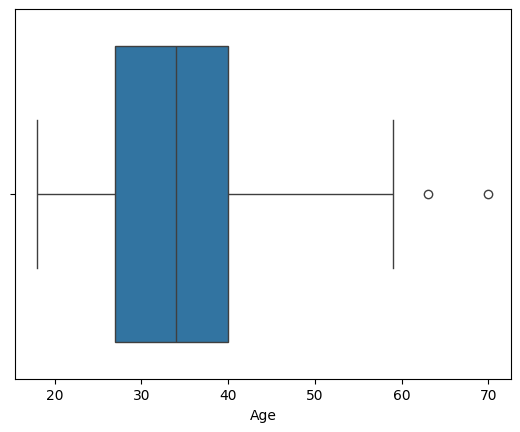

In [21]:
sns.boxplot(x='Age', data=df)

plt.show()

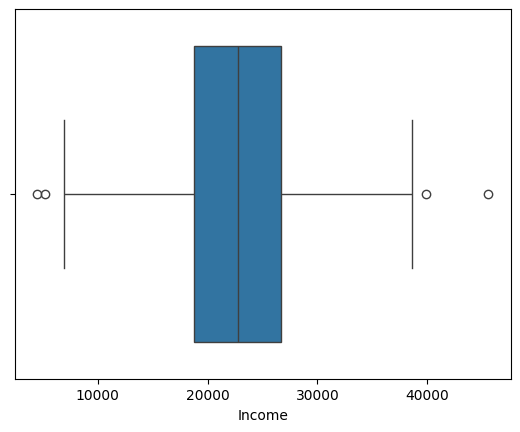

In [22]:
sns.boxplot(x='Income', data=df)

plt.show()

In [23]:
Q1_age = df['Age'].quantile(0.25)
Q3_age = df['Age'].quantile(0.75)
IQR_age = Q3_age - Q1_age

lower_bound_age = Q1_age - 1.5 * IQR_age
upper_bound_age = Q3_age + 1.5 * IQR_age

age_outliers = df[(df['Age'] < lower_bound_age) | (df['Age'] > upper_bound_age)]

age_outliers

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0210,70,45548.0,Yes,Yes,No,No,No,Yes,No,Yes,No,No
C0478,63,30264.0,No,No,No,No,No,Yes,No,No,No,No


In [24]:
Q1_income = df['Income'].quantile(0.25)
Q3_income = df['Income'].quantile(0.75)
IQR_income = Q3_income - Q1_income

lower_bound_income = Q1_income - 1.5 * IQR_income
upper_bound_income = Q3_income + 1.5 * IQR_income

income_outliers = df[(df['Income'] < lower_bound_income) | (df['Income'] > upper_bound_income)]

income_outliers

,Age,Income,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries,Zero-Balance_Cardholder
Customer_ID,,,,,,,,,,,,
C0210,70,45548.0,Yes,Yes,No,No,No,Yes,No,Yes,No,No
C0324,24,5211.0,No,No,No,No,No,No,No,No,No,No
C0578,20,4515.0,No,Yes,No,No,No,Yes,No,No,No,Yes
C0605,51,39900.0,Yes,No,No,No,No,No,No,No,Yes,No


In [25]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score

In [26]:
df.shape

(774, 12)

In [27]:
columns_clustering = ['Age','Income']

df_clustering = df[columns_clustering]

df_clustering.head()

,Age,Income
Customer_ID,,
C0001,38,23357.0
C0002,32,21379.0
C0003,40,27831.0
C0004,48,29658.0
C0005,31,15414.0


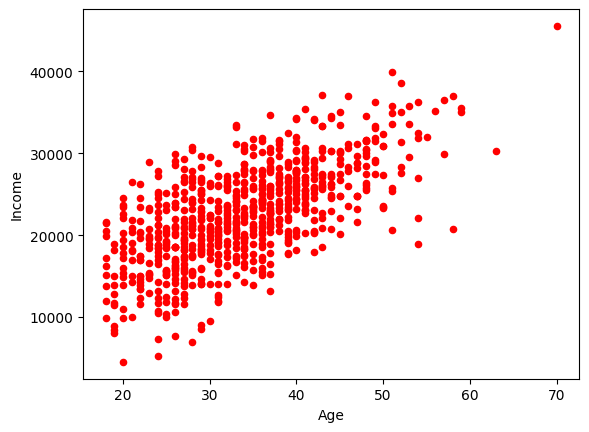

In [28]:
plt.scatter(df_clustering['Age'], df_clustering['Income'], c='red', s=20)

plt.xlabel('Age')
plt.ylabel('Income')

plt.show()

In [29]:
scaler = MinMaxScaler()

df_normalised = scaler.fit_transform(df_clustering)

df_normalised = pd.DataFrame(df_normalised, columns=df_clustering.columns)

df_normalised.head()

,Age,Income
0,0.384615,0.459191
1,0.269231,0.410986
2,0.423077,0.568226
3,0.576923,0.612751
4,0.250000,0.265615


In [30]:
k = 2

model = KMeans(n_clusters=k, random_state=42)

model

KMeans(n_clusters=2, random_state=42)

In [31]:
labels = model.fit_predict(df_normalised)

labels

array([0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1,
       1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0,
       1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0,
       0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1,

In [32]:
normalised_centroids = model.cluster_centers_
centroids = scaler.inverse_transform(normalised_centroids)

centroids

array([[   41.25348189, 27078.61559889],
       [   27.63855422, 18890.37108434]])

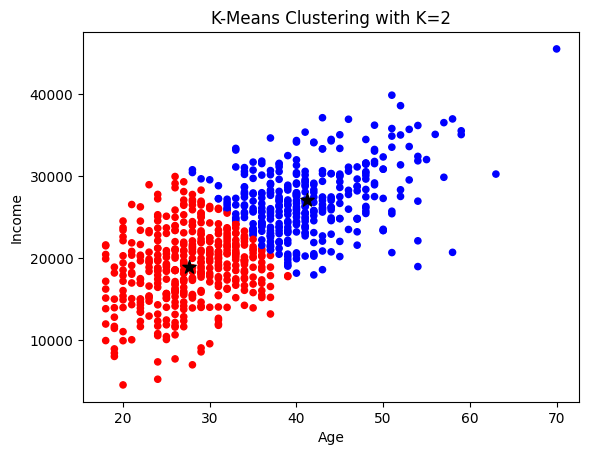

In [33]:
c = ['b', 'r', 'y', 'g', 'c', 'm']
colours = [c[i] for i in labels]

plt.scatter(df['Age'], df['Income'], c=colours, s=20)
plt.scatter(centroids[:,0], centroids[:,1], marker='*', s=100, c='black')

plt.title('K-Means Clustering with K=2')
plt.xlabel('Age')
plt.ylabel('Income')

plt.show()

In [34]:
silhouette_score(df_normalised, labels)

np.float64(0.4544859485824965)

In [35]:
for k in range (2, 7):
    kmeans = KMeans(n_clusters=k, random_state=42)

    kmeans = kmeans.fit(df_normalised)

    print(f'Average Silhouette coefficient for k={k}: {silhouette_score(df_normalised, kmeans.labels_)}')

Average Silhouette coefficient for k=2: 0.4544859485824965
Average Silhouette coefficient for k=3: 0.36644779688865553
Average Silhouette coefficient for k=4: 0.3250023551837589
Average Silhouette coefficient for k=5: 0.3532778211134028
Average Silhouette coefficient for k=6: 0.33649137554717723


In [36]:
#Create a new column named Cluster in the df_clustering DataFrame
#The values for this column are taken from the labels variable, which contains the cluster assignments(e.g., 0,1) that were generated by the K-Means clustering algorithm for each data point
df_clustering['Cluster'] = labels

df_clustering.head()

/tmp/ipykernel_596/301595428.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clustering['Cluster'] = labels


,Age,Income,Cluster
Customer_ID,,,
C0001,38,23357.0,0
C0002,32,21379.0,1
C0003,40,27831.0,0
C0004,48,29658.0,0
C0005,31,15414.0,1


In [37]:
df_clustering['Cluster'].replace(0, 'Older, Higher Income', inplace=True)
df_clustering['Cluster'].replace(1, 'Younger, Lower Income', inplace=True)

df_clustering.head()

/tmp/ipykernel_596/458623128.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clustering['Cluster'].replace(0, 'Older, Higher Income', inplace=True)
/tmp/ipykernel_596/458623128.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clustering['Cluster'].replace(0, 'Older, Higher Income', inplace=True)
/tmp/ipykernel_596/458623128.py:2: 

,Age,Income,Cluster
Customer_ID,,,
C0001,38,23357.0,"Older, Higher Income"
C0002,32,21379.0,"Younger, Lower Income"
C0003,40,27831.0,"Older, Higher Income"
C0004,48,29658.0,"Older, Higher Income"
C0005,31,15414.0,"Younger, Lower Income"


In [38]:
#Calculating the proportion of 'Zero-Balance_Cardholders'='Yes' for each cluster
df_clustering.join(df['Zero-Balance_Cardholder'])[df['Zero-Balance_Cardholder'] == 'Yes']['Cluster'].value_counts(normalize=True) * 100

,proportion
Cluster,
"Younger, Lower Income",75.2
"Older, Higher Income",24.8


In [39]:
#Select only columns that are relevant for association analysis
columns_association = ['Home_Appliances','Fitness_Gadgets','Dining_Vouchers','Travel_Packages','Insurance_Plans','Electronics','Entertainment','Beauty_Wellness','Groceries']

#Combines the df_clustering DataFrame which has the cluster assignments with the df_zerobalance DataFrame
df_clustered = df_clustering.join(df[columns_association])

df_clustered.head()

,Age,Income,Cluster,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries
Customer_ID,,,,,,,,,,,,
C0001,38,23357.0,"Older, Higher Income",Yes,No,No,No,No,Yes,No,No,No
C0002,32,21379.0,"Younger, Lower Income",Yes,No,No,No,No,No,No,No,No
C0003,40,27831.0,"Older, Higher Income",No,Yes,No,No,No,No,No,Yes,No
C0004,48,29658.0,"Older, Higher Income",Yes,Yes,No,No,No,No,No,No,Yes
C0005,31,15414.0,"Younger, Lower Income",No,Yes,Yes,No,No,Yes,No,Yes,Yes


In [40]:
#import mlxtend
from mlxtend.frequent_patterns import apriori, association_rules

In [41]:
#Select only columns that are relevant for association analysis
df_association = df_clustered[columns_association]

df_association.head()

,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries
Customer_ID,,,,,,,,,
C0001,Yes,No,No,No,No,Yes,No,No,No
C0002,Yes,No,No,No,No,No,No,No,No
C0003,No,Yes,No,No,No,No,No,Yes,No
C0004,Yes,Yes,No,No,No,No,No,No,Yes
C0005,No,Yes,Yes,No,No,Yes,No,Yes,Yes


In [42]:
df_association.shape

(774, 9)

In [43]:
df_association.dtypes

,0
Home_Appliances,object
Fitness_Gadgets,object
Dining_Vouchers,object
Travel_Packages,object
Insurance_Plans,object
Electronics,object
Entertainment,object
Beauty_Wellness,object
Groceries,object


In [44]:
for col in df_association.columns:
    df_association[col] = df_association[col].map({'Yes':True, 'No': False})

df_association.head()

/tmp/ipykernel_596/2304414118.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_association[col] = df_association[col].map({'Yes':True, 'No': False})
/tmp/ipykernel_596/2304414118.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_association[col] = df_association[col].map({'Yes':True, 'No': False})
/tmp/ipykernel_596/2304414118.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats i

,Home_Appliances,Fitness_Gadgets,Dining_Vouchers,Travel_Packages,Insurance_Plans,Electronics,Entertainment,Beauty_Wellness,Groceries
Customer_ID,,,,,,,,,
C0001,True,False,False,False,False,True,False,False,False
C0002,True,False,False,False,False,False,False,False,False
C0003,False,True,False,False,False,False,False,True,False
C0004,True,True,False,False,False,False,False,False,True
C0005,False,True,True,False,False,True,False,True,True


In [45]:
df_association.sum()

,0
Home_Appliances,382
Fitness_Gadgets,312
Dining_Vouchers,303
Travel_Packages,65
Insurance_Plans,145
Electronics,332
Entertainment,23
Beauty_Wellness,77
Groceries,368


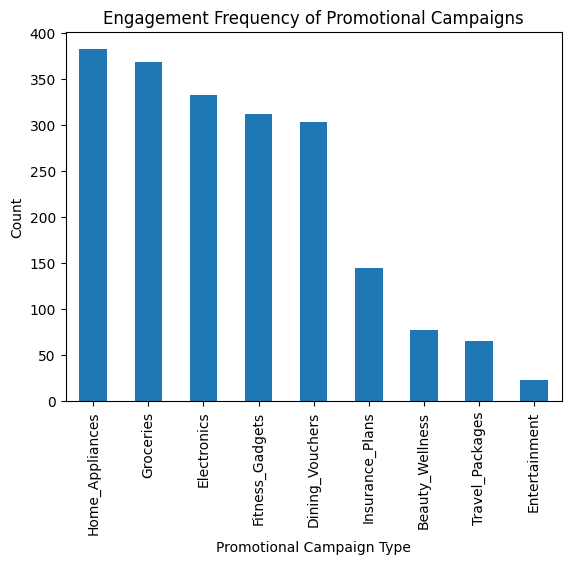

In [46]:
# Plot the bar chart
df_association.sum().sort_values(ascending=False).plot(kind='bar')

# Add a title and labels
plt.title('Engagement Frequency of Promotional Campaigns')
plt.xlabel('Promotional Campaign Type')
plt.ylabel('Count')


# Display the plot
plt.show()

In [47]:
# Perform the Apriori algorithm and find frequent itemsets
frequent_itemsets = apriori(df=df_association, min_support = 0.1, use_colnames=True).sort_values('support', ascending=False)

# Display the frequent itemsets
frequent_itemsets

,support,itemsets
0,0.493540,(Home_Appliances)
5,0.475452,(Groceries)
4,0.428941,(Electronics)
1,0.403101,(Fitness_Gadgets)
2,0.391473,(Dining_Vouchers)
9,0.257106,"(Home_Appliances, Electronics)"
10,0.244186,"(Home_Appliances, Groceries)"
20,0.232558,"(Groceries, Electronics)"
11,0.229974,"(Dining_Vouchers, Fitness_Gadgets)"
13,0.220930,"(Electronics, Fitness_Gadgets)"


In [48]:
# Generate association rules from the frequent itemsets
rules = association_rules(df=frequent_itemsets, metric='confidence', min_threshold=0.75).sort_values('confidence', ascending=False)

# Display the generated association rules

#Display the rules
rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,"(Insurance_Plans, Home_Appliances)",(Electronics),0.134367,0.428941,0.105943,0.788462,1.838160,1.0,0.048308,2.699554,0.526756,0.231638,0.629568,0.517725
1,"(Insurance_Plans, Electronics)",(Home_Appliances),0.138243,0.493540,0.105943,0.766355,1.552772,1.0,0.037715,2.167649,0.413098,0.201474,0.538671,0.490507
3,"(Dining_Vouchers, Home_Appliances, Groceries)",(Electronics),0.135659,0.428941,0.102067,0.752381,1.754045,1.0,0.043878,2.306202,0.497361,0.220670,0.566387,0.495166
2,"(Home_Appliances, Fitness_Gadgets, Electronics)",(Dining_Vouchers),0.139535,0.391473,0.104651,0.750000,1.915842,1.0,0.050027,2.434109,0.555556,0.245455,0.589172,0.508663
